# IQ blob (two-state readout discrimination)

In [1]:
from pathlib import Path

from qblox_lab.config.device import save_device_configuration
from qblox_lab.config.hardware import create_hardware_agent
from qblox_lab.config.sessions import CONFIG_DIR, SESSIONS
from qblox_lab.config.session_paths import save_config_snapshot, save_result_figures
from qblox_lab.experiments.cal13_iq_blob import IQBlob

## Run parameters

In [9]:
SESSION = SESSIONS["AS_QRC"]
HARDWARE_CONFIG = SESSION.hardware_config
DEVICE_CONFIG = SESSION.device_config
FLUX_CONFIG = SESSION.flux_config  # If None, leave the existing hardware flux unchanged
OUTPUT_DIR = SESSION.output_dir
EXPERIMENT_NAME = "iq_blob"

QUBITS = ["q1"]
REPETITIONS = 4000
RESET_TYPE = "thermal"  # "thermal" or "active" (ConditionalReset)
ACTIVE_RESET_BUFFER = 0  # s, idle buffer after active reset before the next pulse/measure
                            # (lets readout-resonator photons from ConditionalReset decay;
                            # only used when RESET_TYPE == "active")
MULTIPLEXED = False  # True: drive/read out all qubits together (with crosstalk).
                     # False: each qubit's full protocol runs in isolation.

TIMEOUT = 300
CREATE_DUMMY_CONNECTIONS = False

PLOT_RESULTS = True
SAVE_FITTED_DEVICE = SESSION.device_config # Use None to skip persistence

## Hardware and experiment

In [10]:
import atexit

from qcodes.instrument import Instrument

hardware_agent = create_hardware_agent(
    hardware_configuration=HARDWARE_CONFIG,
    device_configuration=DEVICE_CONFIG,
    output_dir=OUTPUT_DIR,
    create_dummy_connections=CREATE_DUMMY_CONNECTIONS,
)

experiment = IQBlob(
    hardware_agent=hardware_agent,
    qubits=QUBITS,
    flux_config=FLUX_CONFIG,
)

atexit.register(Instrument.close_all)

<bound method Instrument.close_all of <class 'qcodes.instrument.instrument.Instrument'>>

## Measurement

In [11]:
dataset = experiment.run_measurement(
    repetitions=REPETITIONS,
    reset_type=RESET_TYPE,
    active_reset_buffer=ACTIVE_RESET_BUFFER,
    multiplexed=MULTIPLEXED,
    timeout=TIMEOUT,
)
dataset

<xarray.Dataset> Size: 320kB
Dimensions:           (acq_index_S21_q1: 8000)
Coordinates:
  * acq_index_S21_q1  (acq_index_S21_q1) int64 64kB 0 1 2 3 ... 7997 7998 7999
    state_q1          (acq_index_S21_q1) int64 64kB 0 1 0 1 0 1 ... 0 1 0 1 0 1
    rep_q1            (acq_index_S21_q1) int64 64kB 0 0 1 1 ... 3998 3999 3999
Data variables:
    S21_q1            (acq_index_S21_q1) complex128 128kB (-0.000144704699516...
Attributes:
    tuid:     20261016-035718-391-7bb8cb

## Optional: Simulated data

In [5]:
# dataset = experiment.simulated_data(
#     repetitions=REPETITIONS,
#     ground_iq=0.0,
#     excited_iq=0.3 + 0.2j,
#     assignment_fidelity=0.97,
#     noise=0.03,
#     seed=42,
# )

## Analysis

In [12]:
results = experiment.analysis()
failed_qubits = [qubit for qubit, result in results.items() if not result.success]
if failed_qubits:
    print(f"Discriminator fit failed for: {failed_qubits}")
# Per-qubit readout fidelity is shown on the plot below.

In [13]:
print(results[QUBITS[0]].acq_rotation_degrees)
print(results[QUBITS[0]].acq_threshold)

65.34052741743358
0.0001550614312364777


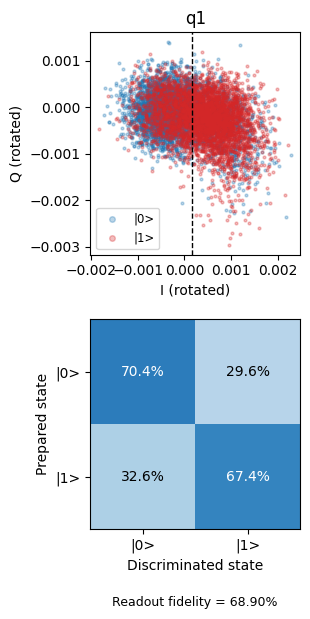

In [15]:
if PLOT_RESULTS:
    experiment.plot()

## Optional: device update

In [16]:
if SAVE_FITTED_DEVICE is not None:
    experiment.update_device()
    saved_path = save_device_configuration(
        hardware_agent.quantum_device,
        SAVE_FITTED_DEVICE,
    )
    print(f"Updated device configuration saved to {saved_path}")

Updated device configuration saved to /home/boris0403/qblox-measurement-nodes/config/10Q9C/dut_config_AS_QRC.json


In [17]:
if PLOT_RESULTS and experiment.figures:
    save_result_figures(SESSION, dataset, EXPERIMENT_NAME, experiment.figures)
save_config_snapshot(SESSION, dataset, EXPERIMENT_NAME)


## Release hardware connection

In [ ]:
from qcodes.instrument import Instrument

Instrument.close_all()